<a href="https://colab.research.google.com/github/AfraazUlHaque/Non-Linear-SVM/blob/main/BANKMARKETING_nlsvm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


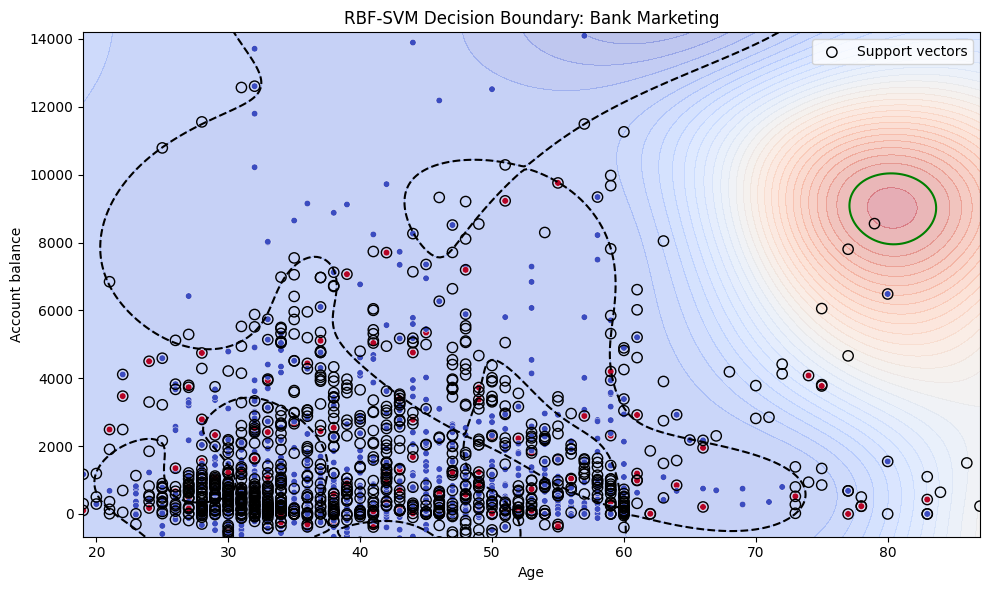

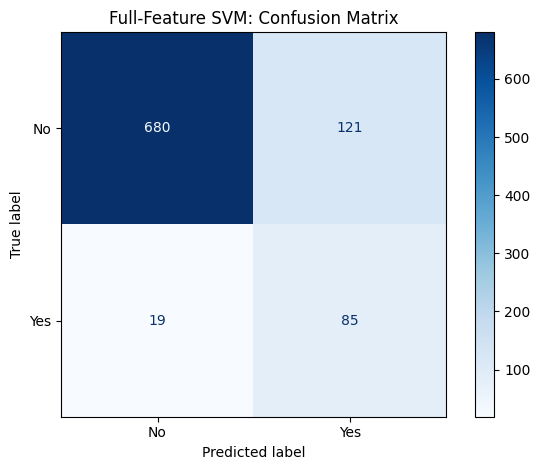

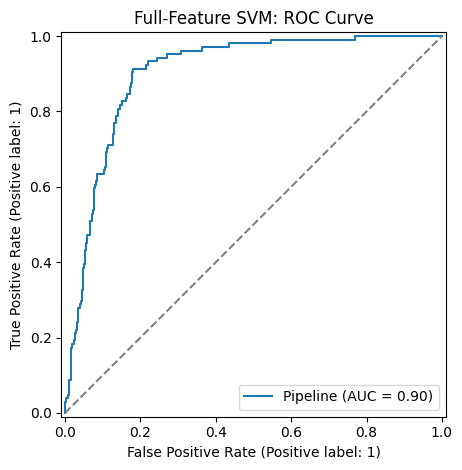

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# =====================================
# VISUAL 1: NON-LINEAR DECISION BOUNDARY
# =====================================

features = ["age", "balance"]

X2 = X[features]
y2 = y

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.20,
    random_state=42,
    stratify=y2
)

svm_2d = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1, gamma="scale")
)

svm_2d.fit(X2_train, y2_train)

# Create grid in original feature coordinates
x_min, x_max = X2["age"].min(), X2["age"].max()
y_min, y_max = X2["balance"].quantile(0.01), X2["balance"].quantile(0.99)

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
decision = svm_2d.decision_function(
    grid
).reshape(xx.shape)

plt.figure(figsize=(10, 6))

plt.contourf(
    xx, yy, decision,
    levels=30, cmap="coolwarm", alpha=0.35
)

plt.contour(
    xx, yy, decision,
    levels=[-1, 0, 1],
    colors=["black", "green", "black"],
    linestyles=["--", "-", "--"]
)

# Plot a sample of training observations
rng = np.random.RandomState(42)
idx = rng.choice(
    len(X2_train),
    size=min(1200, len(X2_train)),
    replace=False
)

plt.scatter(
    X2_train.iloc[idx, 0],
    X2_train.iloc[idx, 1],
    c=y2_train.iloc[idx],
    cmap="coolwarm",
    edgecolors="white",
    linewidths=0.3,
    s=22
)

# Highlight support vectors
scaler = svm_2d.named_steps["standardscaler"]
svc = svm_2d.named_steps["svc"]

support_original = scaler.inverse_transform(
    svc.support_vectors_
)

plt.scatter(
    support_original[:, 0],
    support_original[:, 1],
    s=55,
    facecolors="none",
    edgecolors="black",
    linewidths=1,
    label="Support vectors"
)

plt.ylim(y_min, y_max)
plt.xlabel("Age")
plt.ylabel("Account balance")
plt.title("RBF-SVM Decision Boundary: Bank Marketing")
plt.legend()
plt.tight_layout()
plt.show()


# =====================================
# VISUAL 2: CONFUSION MATRIX
# Full-feature tuned model from previous code
# =====================================

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Full-Feature SVM: Confusion Matrix")
plt.tight_layout()
plt.show()


# =====================================
# VISUAL 3: ROC CURVE
# =====================================

RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.title("Full-Feature SVM: ROC Curve")
plt.tight_layout()
plt.show()